<a href="https://colab.research.google.com/github/Azidian/Inteligencia_Artificial/blob/main/Componente_practico/Lecture_06/Challenge/03_evaluation_deployment_challenge.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Challenge 3: evaluación final e inferencia

El modelo ya fue seleccionado. Ahora debes abrir el conjunto de test una sola vez, comunicar su desempeño y comprobar que el pipeline puede reutilizarse con datos nuevos.

**Entradas:** `test.csv`, `data_contract.json` y `champion_model.joblib`  
**Salidas:** `test_metrics.json`, `batch_predictions.csv`

In [4]:
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    f1_score,
)

In [5]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

RAW_DATA_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_DIR / "data" / "processed"
ARTIFACTS_DIR = PROJECT_DIR / "artifacts"
REPORTS_DIR = PROJECT_DIR / "reports"

for directory in (PROCESSED_DATA_DIR, ARTIFACTS_DIR, REPORTS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

## 1. Carga del modelo y del conjunto de prueba

In [6]:
contract = json.loads((ARTIFACTS_DIR / "data_contract.json").read_text(encoding="utf-8"))
training_metadata = json.loads((ARTIFACTS_DIR / "training_metadata.json").read_text(encoding="utf-8"))
model = joblib.load(ARTIFACTS_DIR / "champion_model.joblib")

test_df = pd.read_csv(PROCESSED_DATA_DIR / "test.csv")
X_test = test_df[contract["features"]]
y_test = test_df[contract["target"]]

print("Modelo:", training_metadata["champion"])
print("Test:", X_test.shape)

Modelo: LogisticRegression
Test: (36, 13)


## 2. Evaluación final

Accuracy test: 0.9722
F1 macro test: 0.971

Classification report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        12
           1       0.93      1.00      0.97        14
           2       1.00      0.90      0.95        10

    accuracy                           0.97        36
   macro avg       0.98      0.97      0.97        36
weighted avg       0.97      0.97      0.97        36



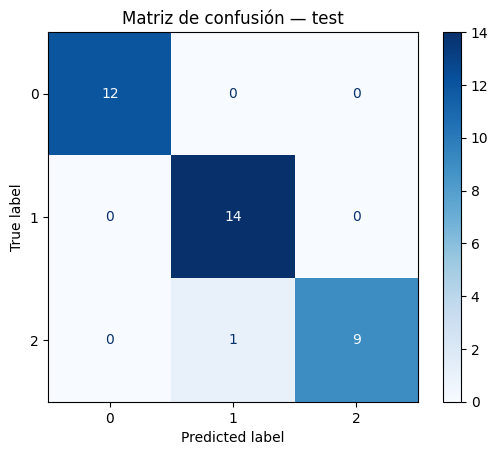

In [7]:
y_pred = model.predict(X_test)

acc = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred, average="macro")

print("Accuracy test:", round(acc, 4))
print("F1 macro test:", round(f1, 4))
print("\nClassification report:")
print(classification_report(y_test, y_pred))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues")
plt.title("Matriz de confusión — test")
plt.show()

**Análisis:**

> **¿El desempeño es coherente con validación cruzada?** Sí. En test el modelo obtuvo accuracy de 0.972 y F1 macro de 0.971, muy cerca del 0.979 que se había visto en CV. La diferencia es de menos de un punto porcentual.
>
> **¿Qué clases se confunden?** Solo hubo un error de 36 muestras: un vino de la **clase 2** fue clasificado como **clase 1**. Por eso la clase 2 tiene recall de 0.90 y la clase 1 precisión de 0.93. La clase 0 se clasificó de manera correcta.
>
> **¿Hay evidencia de sobreajuste?** No se encuentra alguna muy relevante. Si el modelo estuviera muy sobreajustado, el desempeño en test caería mucho respecto a CV, y es casi igual. Aun así hay que tener en cuenta que el test tiene solo 36 muestras, así que un solo error mueve el accuracy casi 3 puntos, y la estimación es poco precisa.

## 3. Función de inferencia

In [8]:
feature_columns = contract["features"]

def predict(records: pd.DataFrame) -> pd.DataFrame:
    """Valida el esquema y devuelve las predicciones del pipeline."""
    # Verifica columnas faltantes
    missing = [c for c in feature_columns if c not in records.columns]
    if missing:
        raise ValueError(f"Faltan columnas requeridas: {missing}")

    # Ordena las columnas como feature_columns (ignora columnas extra)
    X = records[feature_columns]

    # Devuelve prediction y probabilidades
    out = pd.DataFrame({"prediction": model.predict(X)}, index=records.index)
    probas = model.predict_proba(X)
    for i, cls in enumerate(model.classes_):
        out[f"proba_class_{cls}"] = probas[:, i]
    return out

## 4. Predicción por lotes

In [9]:
# Simulación de datos nuevos. En producción no provendrían del test set.
new_records = X_test.iloc[:5].copy()

batch_predictions = predict(new_records)
batch_predictions.to_csv(REPORTS_DIR / "batch_predictions.csv", index=False)
batch_predictions.round(3)

,prediction,proba_class_0,proba_class_1,proba_class_2
0,0,1.000,0.000,0.000
1,1,0.007,0.540,0.453
2,0,0.992,0.008,0.000
3,1,0.290,0.707,0.003
4,1,0.033,0.962,0.005


## 5. Reporte final

In [10]:
test_metrics = {
    "model": training_metadata["champion"],
    "accuracy": float(acc),
    "f1_macro": float(f1),
}
(REPORTS_DIR / "test_metrics.json").write_text(
    json.dumps(test_metrics, indent=2), encoding="utf-8"
)
print(json.dumps(test_metrics, indent=2))

# Prueba de validación del esquema: debe fallar si falta una columna
try:
    predict(new_records.drop(columns=["proline"]))
except ValueError as e:
    print("\nValidación OK ->", e)

{
  "model": "LogisticRegression",
  "accuracy": 0.9722222222222222,
  "f1_macro": 0.9709618874773139
}

Validación OK -> Faltan columnas requeridas: ['proline']


In [11]:
assert (REPORTS_DIR / "test_metrics.json").exists()
assert (REPORTS_DIR / "batch_predictions.csv").exists()
print("Challenge 3 completado.")

Challenge 3 completado.


## Resumen ejecutivo

| Elemento | Resultado |
|---|---|
| Modelo campeón | LogisticRegression (C = 1) con StandardScaler |
| Accuracy CV | 0.979 (± 0.028) |
| Accuracy test | 0.972 |
| F1 macro test | 0.971 |
| Clases más confundidas | Clase 2 confundida con clase 1 (1 caso) |
| Principal limitación | Conjunto de test muy pequeño (36 muestras) y dataset de solo 178 vinos, por lo que las métricas tienen alta incertidumbre y pueden no generalizar a otros orígenes de vino |

## Checklist

- [x] Evalué únicamente el modelo campeón.
- [x] No reajusté hiperparámetros después de observar test.
- [x] Implementé validación básica del esquema de entrada.
- [x] Generé predicciones por lotes.
- [x] Guardé las métricas finales.